[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/causal.ipynb)

# Causal features: no look-ahead

Features that are used to predict day `t + 1` must not use data after day `t`. An ordinary `tc.features` call does use later data, even with a backward kernel: its reducers are fitted on the whole recording. With `causal=True`, row `t` of every output is computed from rows `0..t` only.

This notebook shows that on 20 years of daily returns of 49 US industries, the data of the [stock-market tutorial](stocks.ipynb): the look-ahead of an ordinary call, reducers fitted on a training span and applied to later days, the first rows without enough history, refits, and what causal mode does not accept. It shows the features and the guarantee; it makes no forecast.

**Data.** The "49 Industry Portfolios" of the [Kenneth R. French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), downloaded once (about 4 MB) into a cache folder (`TIMECORR_DATA`, default `~/timecorr_data`). The last cell prints the notebook's run time.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.4.0 or
# later from PyPI, or, when pip cannot install that (it then prints an error first),
# the master branch on GitHub.
import sys

if 'google.colab' in sys.modules:
    !pip install -q "timecorr>=0.4.0" || pip install -q "timecorr @ git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import pickle
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
plt.style.use('timecorr.tutorial')
COLORS = plt.rcParams['axes.prop_cycle'].by_key()['color']
# Every call below has first rows with fewer than 3 past samples, and timecorr warns
# about them at each step. Section 3 counts those rows, so that one warning is not shown.
warnings.filterwarnings('ignore', message='.*timepoints have fewer than 3')
NOTEBOOK_START = time.time()
print('timecorr', tc.__version__)

timecorr 0.4.0


## The data

`tc.datasets.industry_returns` returns the daily log returns as a DataFrame. The reducers will be fitted on the days before 2015 (the training span), and the checks of section 1 cut the history at the end of 2019.

In [3]:
returns = tc.datasets.industry_returns('2005-01-01', '2024-12-31')
x, dates = returns.values, returns.index
n_train = int(dates.searchsorted(pd.Timestamp('2015-01-01')))   # rows before 2015
cut = int(dates.searchsorted(pd.Timestamp('2020-01-01')))       # rows before 2020
print(f'{x.shape[0]} trading days ({dates[0].date()} to {dates[-1].date()}), {x.shape[1]} industries')
print(f'training span: rows 0 to {n_train - 1} (to {dates[n_train - 1].date()}); cut after row {cut - 1} ({dates[cut - 1].date()})')

5033 trading days (2005-01-03 to 2024-12-31), 49 industries
training span: rows 0 to 2516 (to 2014-12-31); cut after row 3774 (2019-12-31)


## 1. The look-ahead of an ordinary call

Both calls below use backward kernels (`include_timepoints='backward'`), so each correlation weights past days only. The second call gets the history without its last five years. If nothing looked ahead, its rows would equal the first rows of the other call.

In [4]:
# Gaussian kernels with a standard deviation of 20 trading days, on both paths
KERNELS = dict(weights_params={'var': 20 ** 2}, delta_weights_params={'var': 20 ** 2})


def compare(a, b, rows, label):
    # per order: the largest absolute difference between the first `rows` rows of two outputs
    for k in (1, 2):
        if a[k].shape[1] != b[k].shape[1]:
            print(f'X[{k}], {label}: {a[k].shape[1]} columns and {b[k].shape[1]} columns')
        else:
            change = np.nanmax(np.abs(a[k][:rows] - b[k][:rows]))
            same = np.array_equal(a[k][:rows], b[k][:rows], equal_nan=True)
            print(f'X[{k}], {label}: largest change {change:.1e} (largest value {np.nanmax(np.abs(a[k])):.1f});'
                  f' rows equal: {same}')


ordinary = dict(order=2, include_timepoints='backward', **KERNELS)
full = tc.features(x, **ordinary)
compare(full, tc.features(x[:cut], **ordinary), cut, 'later days removed')

X[1], later days removed: largest change 1.2e+01 (largest value 18.1); rows equal: False
X[2], later days removed: 20 columns and 18 columns


The cell printed how much the rows before the cut changed, or the two numbers of columns where the calls returned different ones. Now the same with `causal=True`: the reducers are fitted on the first `fit_timepoints` rows and then frozen. The cell removes the days from 2020 on, and then replaces them with random numbers.

In [5]:
causal = dict(order=2, causal=True, fit_timepoints=n_train, **KERNELS)
X, info = tc.features(x, return_info=True, **causal)

compare(X, tc.features(x[:cut], **causal), cut, 'later days removed')
replaced = x.copy()
replaced[cut:] = np.random.default_rng(0).standard_normal(replaced[cut:].shape)
compare(X, tc.features(replaced, **causal), cut, 'later days replaced')

X[1], later days removed: largest change 3.6e-15 (largest value 17.2); rows equal: False
X[2], later days removed: largest change 0.0e+00 (largest value 5.1); rows equal: True


X[1], later days replaced: largest change 0.0e+00 (largest value 17.2); rows equal: True
X[2], later days replaced: largest change 0.0e+00 (largest value 5.1); rows equal: True


What [`tc.features`](https://timecorr.readthedocs.io/en/latest/generated/timecorr.features.html) documents: a row at or after `fit_timepoints` is unchanged bit for bit when later rows are replaced, and to 1e-9 when they are removed. A row inside the training span depends on the training span and on nothing after it.

## 2. Fit on a training span, apply to later days

`return_model=True` also returns the fitted pipeline, a `tc.FeaturesModel`. Here it is fitted on the days before 2015 alone, pickled, and applied to all 20 years with `model.transform`, which fits nothing.

In [6]:
X_train, model = tc.features(x[:n_train], return_model=True, **causal)
print(model, '| a tc.FeaturesModel:', isinstance(model, tc.FeaturesModel), '| fit_timepoints:', model.fit_timepoints)
model = pickle.loads(pickle.dumps(model))            # a model can be pickled, for example to save it after training

start = time.time()
X_later = model.transform(x)
print(f'model.transform: {X_later[1].shape[0]} days in {time.time() - start:.1f} s')
compare(X_later, X, len(x), 'model.transform against section 1')

FeaturesModel(order=2, fit_timepoints=2517, n_features=49, n_subjects=1) | a tc.FeaturesModel: True | fit_timepoints: 2517


model.transform: 5033 days in 2.3 s
X[1], model.transform against section 1: largest change 0.0e+00 (largest value 17.2); rows equal: True
X[2], model.transform against section 1: largest change 0.0e+00 (largest value 5.1); rows equal: True


Three of the features over the 20 years: the first two columns of `X[1]` (principal components of the correlations, fitted on the training span) and the first column of `X[2]`. The values after the shaded span come from reducers that never saw those days.

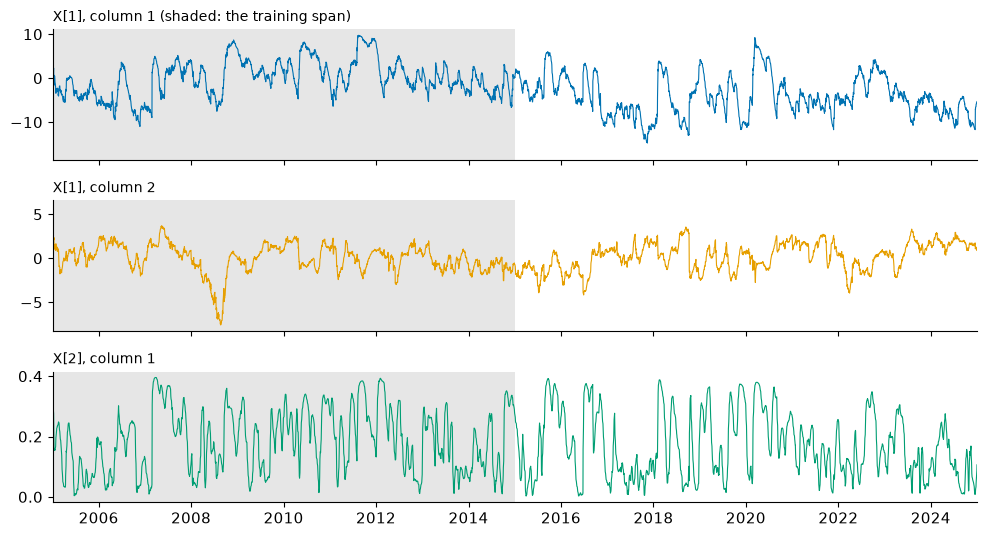

In [7]:
def shade_training(ax):
    ax.axvspan(dates[0], dates[n_train - 1], color='0.9', lw=0)


shown = [(1, 0), (1, 1), (2, 0)]
fig, axes = plt.subplots(len(shown), 1, figsize=(10, 5.5), sharex=True)
for ax, (k, column), color in zip(axes, shown, COLORS):
    shade_training(ax)
    ax.plot(dates, X_later[k][:, column], color=color, lw=0.8)
    ax.set_title(f'X[{k}], column {column + 1}' + (' (shaded: the training span)' if ax is axes[0] else ''),
                 loc='left', fontsize=10)
axes[-1].set_xlim(dates[0], dates[-1])
plt.tight_layout()
plt.show()

## 3. Warm-up rows

A row with fewer than 3 past samples in its kernel is NaN in every column, and the NaN rows of one order are missing data for the next; `return_info=True` counts them per step (`"warmup_rows"`). `min_samples` also asks for an effective number of past samples, `(sum |w|)**2 / sum w**2` over the kernel row.

In [8]:
def warmup(info):
    return ', '.join(f'order {step["order"]} {step["path"]}: {step["warmup_rows"]}' for step in info)


print(f'{"section 1":>16} | {warmup(info)}')
print(f'{"first full row":>16} | X[1]: row {np.isnan(X[1]).any(axis=1).sum()}, X[2]: row {np.isnan(X[2]).any(axis=1).sum()}')
short = {**causal, 'fit_timepoints': 500}                # the first 500 days are enough to count
for min_samples in (None, 10, 25):
    _, short_info = tc.features(x[:500], return_info=True, min_samples=min_samples, **short)
    print(f'min_samples={str(min_samples):>4} | {warmup(short_info)}')

       section 1 | order 1 analysis: 2, order 1 feeding: 2, order 2 analysis: 4
  first full row | X[1]: row 2, X[2]: row 4


min_samples=None | order 1 analysis: 2, order 1 feeding: 2, order 2 analysis: 4


min_samples=  10 | order 1 analysis: 10, order 1 feeding: 10, order 2 analysis: 20


min_samples=  25 | order 1 analysis: 26, order 1 feeding: 26, order 2 analysis: 52


## 4. Refits

`refit_every=m` fits the reducers again every `m` rows, each time on all rows before, and the rows from one fit to the next use the earlier fit. The components and communities of a later fit are matched to those of the fit before. The number of communities is given here (`tc.Communities(n=6)`): when it is counted from the data, as by default, a later fit that finds another number is not used (`"refit_kept_previous"` lists its row).

In [9]:
fixed = {**causal, 'delta_rfun': tc.Communities(n=6)}
start = time.time()
X_frozen = tc.features(x, **fixed)                       # one fit
seconds_one = time.time() - start

start = time.time()
X_refit, info_refit = tc.features(x, refit_every=1000, return_info=True, **fixed)
seconds_refit = time.time() - start
refit_rows = info_refit[0]['refit_rows']
print('"refit_rows":', refit_rows, '=', [str(dates[r].date()) for r in refit_rows])
print('"refit_kept_previous":', info_refit[0]['refit_kept_previous'])
print(f'one fit: {seconds_one:.0f} s; {len(refit_rows)} fits: {seconds_refit:.0f} s')

"refit_rows": [2517, 3517, 4517] = ['2015-01-02', '2018-12-21', '2022-12-12']
"refit_kept_previous": []
one fit: 7 s; 3 fits: 29 s


Each fit is a pass over its rows and one over all rows, so the time grows with the number of fits. The figure follows the first column of `X[1]` around each later fit (dashed line), with one fit (gray) and with refits (blue): after a fit the column is still the same component with the same sign, at somewhat different values. The cell prints its step at each fit next to its usual day-to-day step, and its correlation with the one-fit column from the second fit on.

median day-to-day step: 0.225; step into the row of each later fit: 1.210, 0.332
correlation with the one-fit column from row 3517 on: 0.998


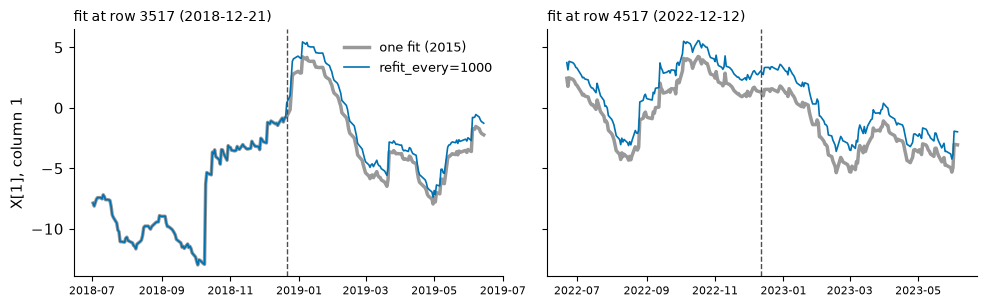

In [10]:
k, column, half = 1, 0, 120
series, frozen = X_refit[k][:, column], X_frozen[k][:, column]
steps = np.abs(np.diff(series))
print(f'median day-to-day step: {np.nanmedian(steps):.3f}; step into the row of each later fit: '
      + ', '.join(f'{steps[r - 1]:.3f}' for r in refit_rows[1:]))
print(f'correlation with the one-fit column from row {refit_rows[1]} on: '
      f'{np.corrcoef(series[refit_rows[1]:], frozen[refit_rows[1]:])[0, 1]:.3f}')

fig, axes = plt.subplots(1, len(refit_rows) - 1, figsize=(10, 3.2), sharey=True)
for ax, r in zip(np.atleast_1d(axes), refit_rows[1:]):
    window = slice(r - half, r + half)
    ax.plot(dates[window], frozen[window], color='0.6', lw=2.5, label='one fit (2015)')
    ax.plot(dates[window], series[window], color=COLORS[0], lw=1.2, label='refit_every=1000')
    ax.axvline(dates[r], color='0.3', ls='--', lw=1)
    ax.set_title(f'fit at row {r} ({dates[r].date()})', loc='left', fontsize=10)
    ax.tick_params(axis='x', labelsize=8)
np.atleast_1d(axes)[0].set_ylabel(f'X[{k}], column {column + 1}')
np.atleast_1d(axes)[0].legend(fontsize=9, loc='best')
plt.tight_layout()
plt.show()

## 5. What causal mode does not accept

Anything that would read later rows raises `ValueError` before any computation, and the message names an alternative. For example, kernel widths are not chosen from the data:

In [11]:
try:
    tc.features(x, order=2, causal=True, fit_timepoints=n_train)   # no kernel parameters
except ValueError as error:
    print(error)

causal=True: weights_params must be given for every order (kernel widths are not chosen from the data, which would read later timepoints); order 1 has none.  Pass for example weights_params={'var': 25} for a Gaussian kernel, {} for a kernel without parameters, or in features an order map that names every order.


The limits, as documented in [`tc.features`](https://timecorr.readthedocs.io/en/latest/generated/timecorr.features.html), [`tc.timecorr`](https://timecorr.readthedocs.io/en/latest/generated/timecorr.timecorr.html) and [`tc.FeaturesModel`](https://timecorr.readthedocs.io/en/latest/generated/timecorr.FeaturesModel.html):

- **Raises `ValueError`:** missing kernel parameters; a forward kernel; `tc.eye_weights` (co-fluctuations use the whole recording); `cfun=tc.wisfc` without fixed `subject_weights`; `events` given as features to segment (give boundaries); a fitted reducer without `fit_timepoints`.
- **Models:** the guarantee covers `'PCA'`, `'IncrementalPCA'`, `'TruncatedSVD'`, `'FastICA'` and `'FactorAnalysis'`. Another linear model (one with `components_`) that passes the checks runs with a warning that the guarantee does not cover it; models such as `'UMAP'` or `'TSNE'` raise `ValueError`.
- **Eigenvector-based graph measures** (`'eigenvector_centrality'`, the PageRank measures) are unchanged when later rows are replaced; when later rows are removed they can change by more than 1e-9 where the leading eigenvalues of a correlation matrix coincide.
- **A function of your own** (`cfun`, `rfun`, `delta_rfun`) runs with a warning that the guarantee does not cover what it does.
- **Infinite samples** and samples above 1e150 in magnitude are missing data, like NaN.

Related: [stock-market correlations](stocks.ipynb), [higher-order correlations](higher_order.ipynb).

The picture on this tutorial's card in the gallery: the first column of `X[1]` from section 2, with the training span shaded.

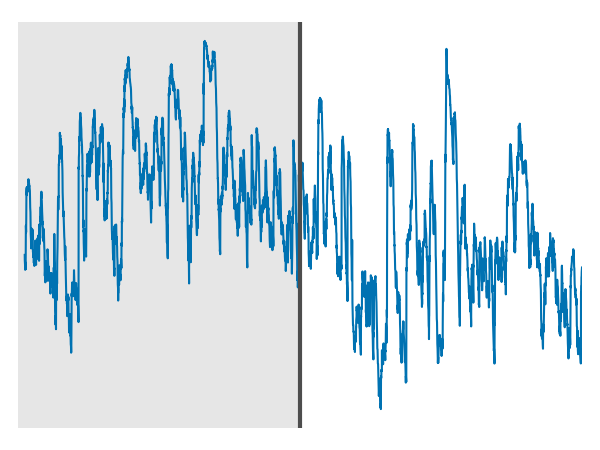

In [12]:
# the saved picture is the whole 4:3 figure (the default crops it to its content)
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}
fig = plt.figure(figsize=(4, 3), dpi=150, facecolor='white')
ax = fig.add_axes([0.03, 0.05, 0.94, 0.9])
shade_training(ax)
first = 60                                              # the first rows, estimated from few days, are left out
ax.plot(dates[first:], X_later[1][first:, 0], color=COLORS[0], lw=1)
ax.axvline(dates[n_train - 1], color='0.3', lw=2)
ax.set_xlim(dates[0], dates[-1])
ax.set_axis_off()
plt.show()

In [13]:
print(f'notebook run time: {time.time() - NOTEBOOK_START:.0f} s')

notebook run time: 99 s
